<a href="https://colab.research.google.com/github/dindaatikah211/leaf-venation-classification/blob/main/Tubes_UTS_Pengolahan_CItra.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install roboflow
from roboflow import Roboflow
rf = Roboflow(api_key="3RLtXZT87ckRN3YwTET8")
project = rf.workspace("dindas-workspace-86v8u").project("leaf-venation-classification")
version = project.version(1)
dataset = version.download("folder")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 249.2/249.2 kB 10.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 17.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 55.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 90.1 MB/s eta 0:00:00
  Attempting uninstall: opencv-python-headless
    Found existing installation: opencv-python-headless 4.13.0.92
    Uninstalling opencv-python-headless-4.13.0.92:
      Successfully uninstalled opencv-python-headless-4.13.0.92
  Attempting uninstall: idna
    Found existing installation: idna 3.15
    Uninstalling idna-3.15:
      Successfully uninstalled idna-3.15
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to leaf-venation-classification-1 in folder:: 100%|██████████| 748/748 [00:00<00:00, 8042.48it/s]


In [ ]:
import os

dataset_path = "/content/leaf-venation-classification-1"

for split in ["train", "valid", "test"]:
    split_path = os.path.join(dataset_path, split)
    print(f"\n{split.upper()}:")
    for cls in os.listdir(split_path):
        cls_path = os.path.join(split_path, cls)
        count = len(os.listdir(cls_path))
        print(f"  {cls}: {count} gambar")


TRAIN:
  arcuate: 156 gambar
  palmate: 162 gambar
  pinnate: 171 gambar
  parallel: 165 gambar

VALID:
  arcuate: 14 gambar
  palmate: 16 gambar
  pinnate: 17 gambar
  parallel: 14 gambar

TEST:
  arcuate: 10 gambar
  palmate: 8 gambar
  pinnate: 6 gambar
  parallel: 8 gambar


In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

# Path dataset
dataset_path = "/content/leaf-venation-classification-1"

# Data Generator
datagen_train = ImageDataGenerator(rescale=1./255)
datagen_val = ImageDataGenerator(rescale=1./255)
datagen_test = ImageDataGenerator(rescale=1./255)

train_data = datagen_train.flow_from_directory(
    dataset_path + "/train",
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical"
)

val_data = datagen_val.flow_from_directory(
    dataset_path + "/valid",
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical"
)

test_data = datagen_test.flow_from_directory(
    dataset_path + "/test",
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    shuffle=False
)

print("Kelas:", train_data.class_indices)

Found 654 images belonging to 4 classes.
Found 61 images belonging to 4 classes.
Found 32 images belonging to 4 classes.
Kelas: {'arcuate': 0, 'palmate': 1, 'parallel': 2, 'pinnate': 3}


In [ ]:
# Build Model MobileNetV2
base_model = MobileNetV2(weights="imagenet", include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False  # Freeze base model

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.3)(x)
output = Dense(4, activation="softmax")(x)

model_mobilenet = Model(inputs=base_model.input, outputs=output)

model_mobilenet.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# Training
history_mobilenet = model_mobilenet.fit(
    train_data,
    epochs=20,
    validation_data=val_data
)

# Simpan model
model_mobilenet.save("mobilenet_leaf.h5")
print("Model MobileNetV2 selesai disimpan!")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 57s 2s/step - accuracy: 0.4128 - loss: 1.3013 - val_accuracy: 0.5574 - val_loss: 1.0171
Epoch 2/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 36s 2s/step - accuracy: 0.6636 - loss: 0.7827 - val_accuracy: 0.6721 - val_loss: 0.7874
Epoch 3/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 33s 2s/step - accuracy: 0.7508 - loss: 0.6153 - val_accuracy: 0.7541 - val_loss: 0.7115
Epoch 4/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 34s 2s/step - accuracy: 0.7997 - loss: 0.5108 - val_accuracy: 0.7869 - val_loss: 0.7031
Epoch 5/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 34s 2s/step - accuracy: 0.8272 - loss: 0.4459 - val_accuracy: 0.7869 - val_loss: 0.6676
Epoch 6/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 36s 2s/step - accuracy: 0.8578 - loss: 0.4028 - val_accuracy: 0.8033 - val_loss: 0.6437
Epoch 7/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 36s 2s/step - accuracy: 0.8807 - loss: 0.3402 - val_accuracy: 0.7377 - val_loss: 0.6470
Epoch 8/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 33s 2s/step - accuracy: 0.8960 

Model MobileNetV2 selesai disimpan!


In [ ]:
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout, BatchNormalization
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Data Generator khusus EfficientNet (tanpa rescale!)
datagen_eff = ImageDataGenerator(preprocessing_function=preprocess_input)

train_eff = datagen_eff.flow_from_directory(
    "/content/leaf-venation-classification-1/train",
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical"
)

val_eff = datagen_eff.flow_from_directory(
    "/content/leaf-venation-classification-1/valid",
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical"
)

# Build Model
base_model2 = EfficientNetB0(weights="imagenet", include_top=False, input_shape=(224, 224, 3))
base_model2.trainable = False

x2 = base_model2.output
x2 = GlobalAveragePooling2D()(x2)
x2 = BatchNormalization()(x2)
x2 = Dropout(0.3)(x2)
output2 = Dense(4, activation="softmax")(x2)

model_efficientnet = Model(inputs=base_model2.input, outputs=output2)

model_efficientnet.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history_efficientnet = model_efficientnet.fit(
    train_eff,
    epochs=20,
    validation_data=val_eff
)

model_efficientnet.save("efficientnet_leaf.h5")
print("Model EfficientNetB0 selesai disimpan!")

Found 654 images belonging to 4 classes.
Found 61 images belonging to 4 classes.
Epoch 1/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 76s 3s/step - accuracy: 0.4434 - loss: 1.4247 - val_accuracy: 0.5246 - val_loss: 1.0120
Epoch 2/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 65s 3s/step - accuracy: 0.7202 - loss: 0.6808 - val_accuracy: 0.6557 - val_loss: 0.8528
Epoch 3/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 76s 3s/step - accuracy: 0.8104 - loss: 0.4907 - val_accuracy: 0.6721 - val_loss: 0.7898
Epoch 4/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 62s 3s/step - accuracy: 0.8394 - loss: 0.4059 - val_accuracy: 0.7213 - val_loss: 0.7238
Epoch 5/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 60s 3s/step - accuracy: 0.8547 - loss: 0.3447 - val_accuracy: 0.8033 - val_loss: 0.6592
Epoch 6/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 58s 3s/step - accuracy: 0.8884 - loss: 0.2987 - val_accuracy: 0.8033 - val_loss: 0.6303
Epoch 7/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 59s 3s/step - accuracy: 0.9006 - loss: 0.2581 - val_accuracy: 0.8033 - val_loss: 0.6111
Epoch 8/20
21/21 ━━━━━━━━━━━━━━━━━━━━

Model EfficientNetB0 selesai disimpan!


Found 32 images belonging to 4 classes.
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step - accuracy: 0.9062 - loss: 0.2848
MobileNetV2 - Test Accuracy: 90.62%
1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step - accuracy: 0.7500 - loss: 0.8485
EfficientNetB0 - Test Accuracy: 75.00%
1/1 ━━━━━━━━━━━━━━━━━━━━ 8s 8s/step


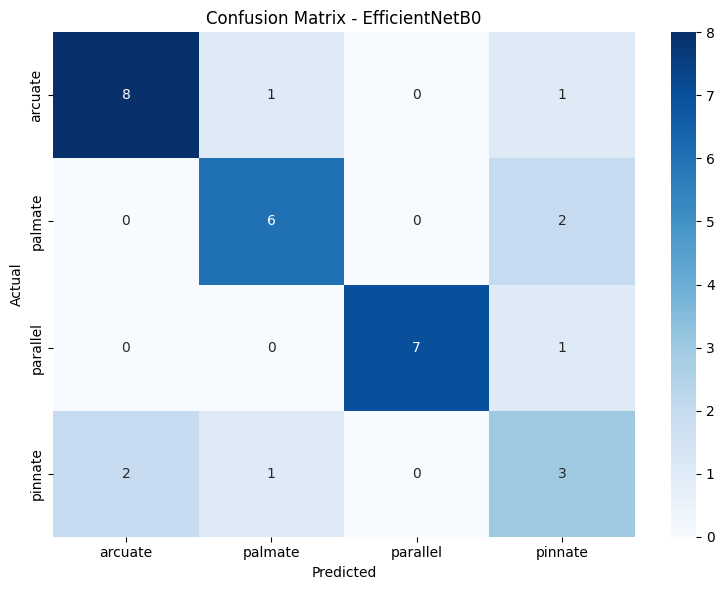


Classification Report - EfficientNetB0:
              precision    recall  f1-score   support

     arcuate       0.80      0.80      0.80        10
     palmate       0.75      0.75      0.75         8
    parallel       1.00      0.88      0.93         8
     pinnate       0.43      0.50      0.46         6

    accuracy                           0.75        32
   macro avg       0.74      0.73      0.74        32
weighted avg       0.77      0.75      0.76        32



In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# Siapkan test data untuk EfficientNet
from tensorflow.keras.applications.efficientnet import preprocess_input as eff_preprocess
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen_test_eff = ImageDataGenerator(preprocessing_function=eff_preprocess)
test_eff = datagen_test_eff.flow_from_directory(
    "/content/leaf-venation-classification-1/test",
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    shuffle=False
)

# Evaluasi MobileNetV2
test_data.reset()
loss_mob, acc_mob = model_mobilenet.evaluate(test_data)
print(f"MobileNetV2 - Test Accuracy: {acc_mob*100:.2f}%")

# Evaluasi EfficientNetB0
test_eff.reset()
loss_eff, acc_eff = model_efficientnet.evaluate(test_eff)
print(f"EfficientNetB0 - Test Accuracy: {acc_eff*100:.2f}%")

# Confusion Matrix EfficientNet
test_eff.reset()
y_pred = model_efficientnet.predict(test_eff)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = test_eff.classes
class_names = list(test_eff.class_indices.keys())

cm = confusion_matrix(y_true, y_pred_classes)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix - EfficientNetB0")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# Classification Report
print("\nClassification Report - EfficientNetB0:")
print(classification_report(y_true, y_pred_classes, target_names=class_names))

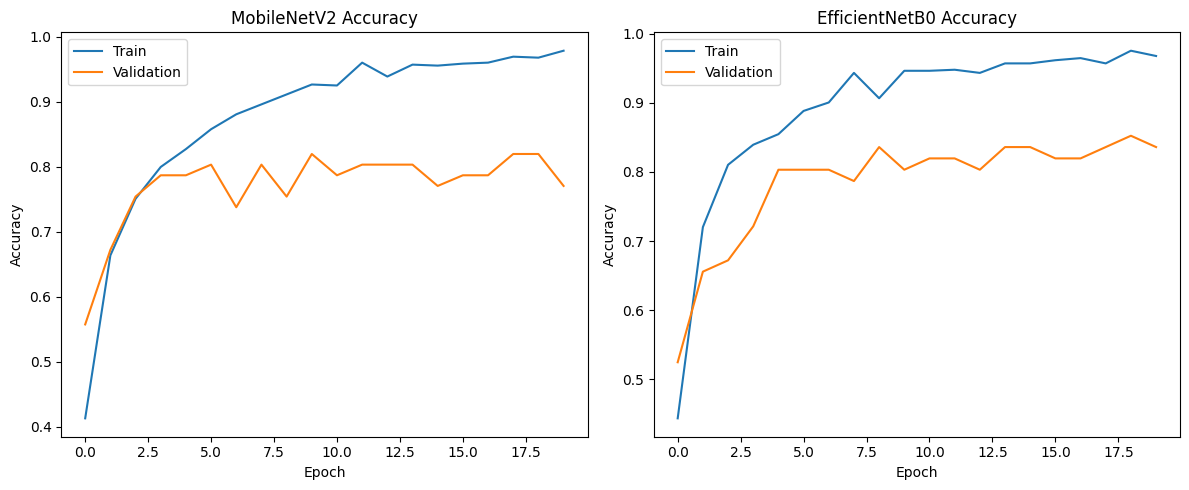

In [ ]:
# Grafik perbandingan akurasi
plt.figure(figsize=(12, 5))

# MobileNetV2
plt.subplot(1, 2, 1)
plt.plot(history_mobilenet.history['accuracy'], label='Train')
plt.plot(history_mobilenet.history['val_accuracy'], label='Validation')
plt.title('MobileNetV2 Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# EfficientNetB0
plt.subplot(1, 2, 2)
plt.plot(history_efficientnet.history['accuracy'], label='Train')
plt.plot(history_efficientnet.history['val_accuracy'], label='Validation')
plt.title('EfficientNetB0 Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
from tensorflow.keras.preprocessing import image
import numpy as np
import matplotlib.pyplot as plt

def predict_leaf(img_path, model, model_name, use_efficientnet=False):
    img = image.load_img(img_path, target_size=(224, 224))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)

    if use_efficientnet:
        from tensorflow.keras.applications.efficientnet import preprocess_input
        img_array = preprocess_input(img_array)
    else:
        img_array = img_array / 255.0

    pred = model.predict(img_array)
    class_names = ['arcuate', 'palmate', 'parallel', 'pinnate']
    pred_class = class_names[np.argmax(pred)]
    confidence = np.max(pred) * 100

    plt.imshow(image.load_img(img_path))
    plt.title(f"{model_name}: {pred_class} ({confidence:.2f}%)")
    plt.axis('off')
    plt.show()

    print(f"Prediksi {model_name}: {pred_class} ({confidence:.2f}%)")

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving IMG_20260518_070130.jpg to IMG_20260518_070130.jpg


1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


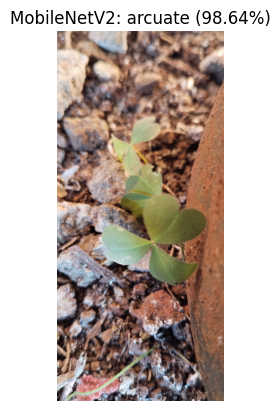

Prediksi MobileNetV2: arcuate (98.64%)
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


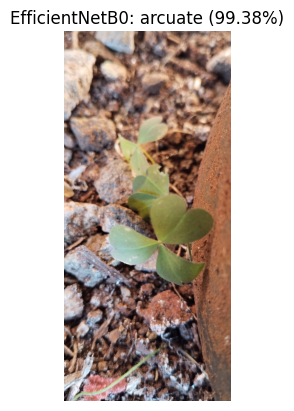

Prediksi EfficientNetB0: arcuate (99.38%)


In [ ]:
predict_leaf("/content/IMG_20260518_070130.jpg", model_mobilenet, "MobileNetV2")
predict_leaf("/content/IMG_20260518_070130.jpg", model_efficientnet, "EfficientNetB0", use_efficientnet=True)

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Hoja de mango_.jpg to Hoja de mango_.jpg


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 188ms/step


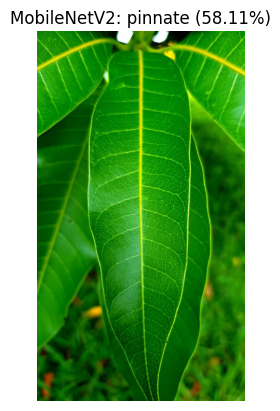

Prediksi MobileNetV2: pinnate (58.11%)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 325ms/step


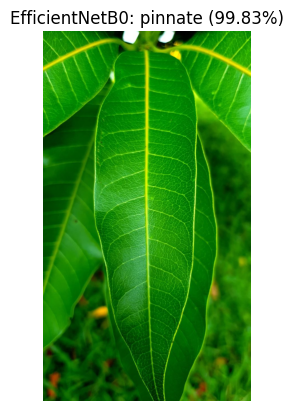

Prediksi EfficientNetB0: pinnate (99.83%)


In [ ]:
predict_leaf("/content/Hoja de mango_.jpg", model_mobilenet, "MobileNetV2")
predict_leaf("/content/Hoja de mango_.jpg", model_efficientnet, "EfficientNetB0", use_efficientnet=True)

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving DAUN SIRIH MERAH SEGAR HARGA UNTUK 10 LEMVAR DAUN.jpg to DAUN SIRIH MERAH SEGAR HARGA UNTUK 10 LEMVAR DAUN.jpg


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 196ms/step


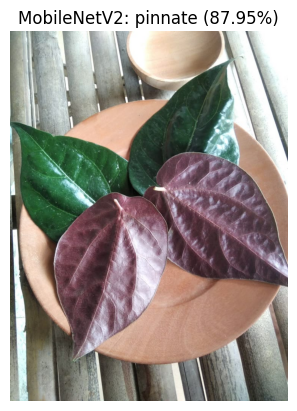

Prediksi MobileNetV2: pinnate (87.95%)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 272ms/step


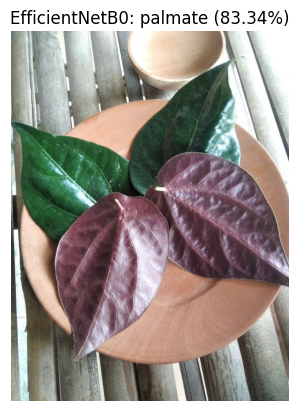

Prediksi EfficientNetB0: palmate (83.34%)


In [ ]:
predict_leaf("/content/DAUN SIRIH MERAH SEGAR HARGA UNTUK 10 LEMVAR DAUN.jpg", model_mobilenet, "MobileNetV2")
predict_leaf("/content/DAUN SIRIH MERAH SEGAR HARGA UNTUK 10 LEMVAR DAUN.jpg", model_efficientnet, "EfficientNetB0", use_efficientnet=True)

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Daun sirih (1).jpg to Daun sirih (1).jpg


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 194ms/step


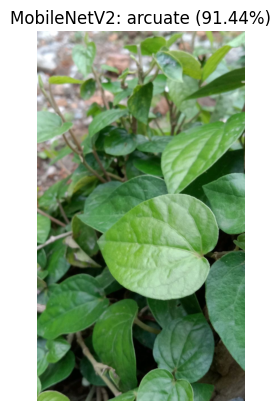

Prediksi MobileNetV2: arcuate (91.44%)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 258ms/step


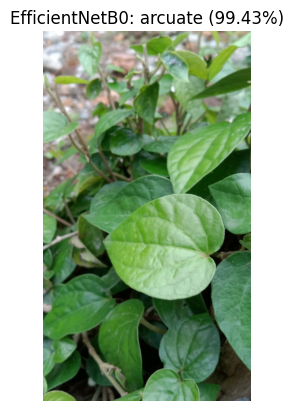

Prediksi EfficientNetB0: arcuate (99.43%)


In [ ]:
predict_leaf("/content/Daun sirih (1).jpg", model_mobilenet, "MobileNetV2")
predict_leaf("/content/Daun sirih (1).jpg", model_efficientnet, "EfficientNetB0", use_efficientnet=True)

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving 624170829651302223.jpg to 624170829651302223.jpg


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 368ms/step


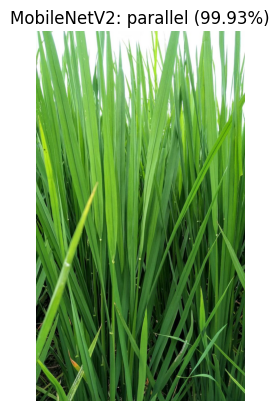

Prediksi MobileNetV2: parallel (99.93%)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 434ms/step


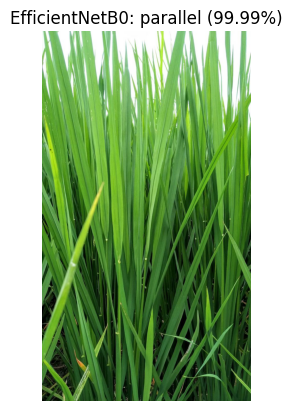

Prediksi EfficientNetB0: parallel (99.99%)


In [ ]:
predict_leaf("/content/624170829651302223.jpg", model_mobilenet, "MobileNetV2")
predict_leaf("/content/624170829651302223.jpg", model_efficientnet, "EfficientNetB0", use_efficientnet=True)